# Task 1: Exploratory Data Analysis (EDA)

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import warnings 
warnings.filterwarnings('ignore')

In [151]:
df = pd.read_csv("car_price.csv")

In [152]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72435 entries, 0 to 72434
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         68814 non-null  str    
 1   year          68813 non-null  float64
 2   price         68814 non-null  float64
 3   transmission  68812 non-null  str    
 4   mileage       68813 non-null  float64
 5   fuelType      68813 non-null  str    
 6   tax           68814 non-null  float64
 7   mpg           68814 non-null  float64
 8   engineSize    68813 non-null  float64
 9   Make          68814 non-null  str    
dtypes: float64(6), str(4)
memory usage: 5.5 MB


In [153]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,68813.000000,68814.000000,68813.000000,68814.000000,68814.000000,68813.000000
mean,2017.077660,16583.919261,23179.439539,116.930421,55.836352,1.635373
std,2.099474,9304.412707,21347.569657,64.081931,17.043643,0.561734
min,1996.000000,495.000000,1.000000,0.000000,0.300000,0.000000
25%,2016.000000,10167.250000,7199.000000,30.000000,47.900000,1.200000
50%,2017.000000,14495.000000,17521.000000,145.000000,55.400000,1.600000
75%,2019.000000,20359.750000,32478.000000,145.000000,62.800000,2.000000
max,2020.000000,145000.000000,323000.000000,580.000000,470.800000,6.600000


In [154]:
df.head()


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Make
0,A1,2017.0,12500.0,Manual,15735.0,Petrol,150.0,55.4,1.4,audi
1,A6,2016.0,16500.0,Automatic,36203.0,Diesel,20.0,64.2,2.0,audi
2,A1,2016.0,11000.0,Manual,29946.0,Petrol,30.0,55.4,1.4,audi
3,A4,2017.0,16800.0,Automatic,25952.0,Diesel,145.0,67.3,2.0,audi
4,A3,2019.0,17300.0,Manual,1998.0,Petrol,145.0,49.6,1.0,audi


In [155]:
df.tail()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Make
72430,I30,2016.0,8680.0,Manual,25906.0,Diesel,0.0,78.4,1.6,Hyundai
72431,I40,2015.0,7830.0,Manual,NaN,Diesel,30.0,65.7,1.7,Hyundai
72432,I10,2017.0,6830.0,Manual,13810.0,Petrol,20.0,60.1,1.0,NaN
72433,Tucson,2018.0,13994.0,Manual,23313.0,Petrol,145.0,44.8,1.6,Hyundai
72434,Tucson,2016.0,15999.0,Automatic,11472.0,Diesel,125.0,57.6,1.7,Hyundai


# 1. How many rows and columns does the dataset have?

In [156]:
print(f'Number of columns : {df.shape[1]}')

Number of columns : 10


In [157]:
print(f'Number of rows : {df.shape[0]}')

Number of rows : 72435


# 2. Which features are numerical? Which are categorical?

In [158]:
numerical = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("Numerical Features",numerical)

Numerical Features ['year', 'price', 'mileage', 'tax', 'mpg', 'engineSize']


In [159]:
categorical = df.select_dtypes(include='object').columns.tolist()
print("Categorical Features:", categorical)

Categorical Features: ['model', 'transmission', 'fuelType', 'Make']


# 3. Are there any missing values? How many, and in which columns?

In [160]:
for col in df.columns:
    print(f"Column : {col}")
    print(f"Number of null values: {df[col].isnull().sum()}")
    print("_"*70)
    print()

Column : model
Number of null values: 3621
______________________________________________________________________

Column : year
Number of null values: 3622
______________________________________________________________________

Column : price
Number of null values: 3621
______________________________________________________________________

Column : transmission
Number of null values: 3623
______________________________________________________________________

Column : mileage
Number of null values: 3622
______________________________________________________________________

Column : fuelType
Number of null values: 3622
______________________________________________________________________

Column : tax
Number of null values: 3621
______________________________________________________________________

Column : mpg
Number of null values: 3621
______________________________________________________________________

Column : engineSize
Number of null values: 3622
_________________________

In [161]:
print(f"Number of duplicates: {df.duplicated().sum()}")

Number of duplicates: 366


# 4. What does the distribution of car prices look like?

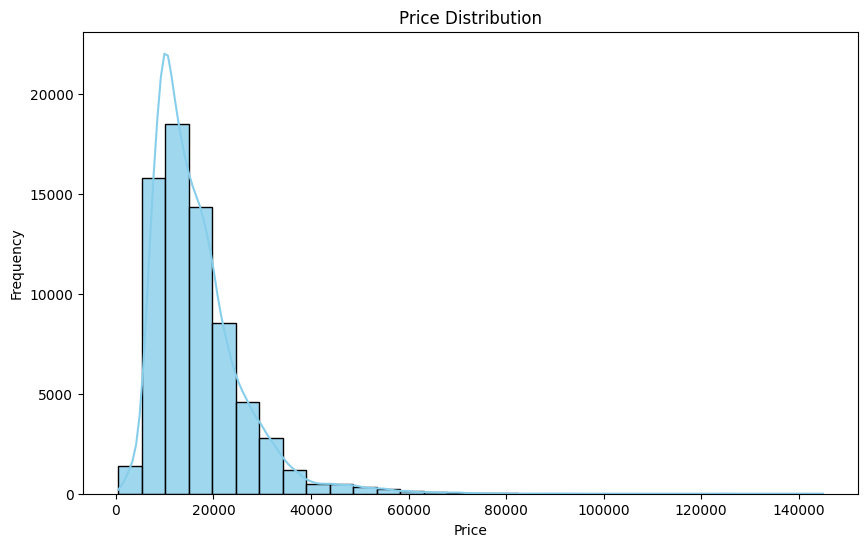

In [162]:
plt.figure(figsize=(10, 6))
sns.histplot(df["price"], bins=30, kde=True, color="skyblue",alpha=0.8)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

# 5. Which features seem most related to price?

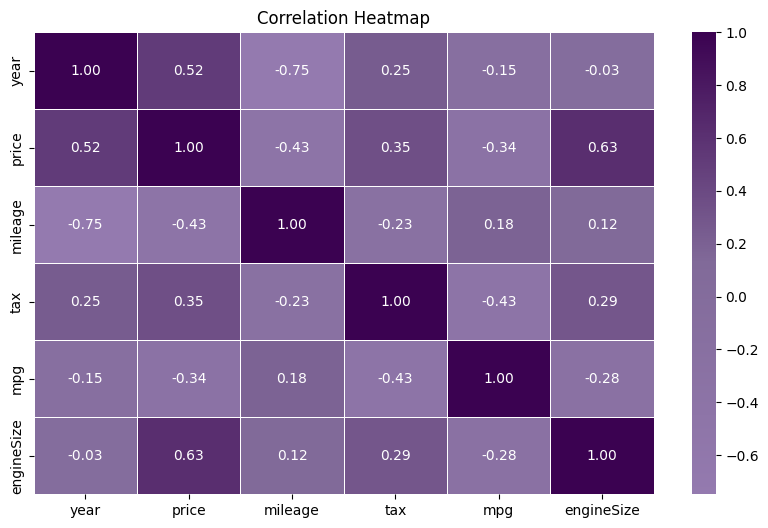

In [163]:
features=numerical
corr = df[features].corr()
plt.figure(figsize=(10,6))
purple = LinearSegmentedColormap.from_list("custom_pink", ["#947aaf", "#816A99", "#3B0251"])
sns.heatmap(corr, annot=True, cmap=purple, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

# Scatter Plots: Numerical Features vs Price

This code creates a set of scatter plots to explore the relationship between different features and the target variable price

Year vs Price : newer cars → higher price (strong positive)

Mileage vs Price : higher mileage → lower price (strong negative)

Tax vs Price : no clear relationship (weak)

MPG vs Price : unclear/weak non-linear effect

Engine Size vs Price : larger engine → higher price 

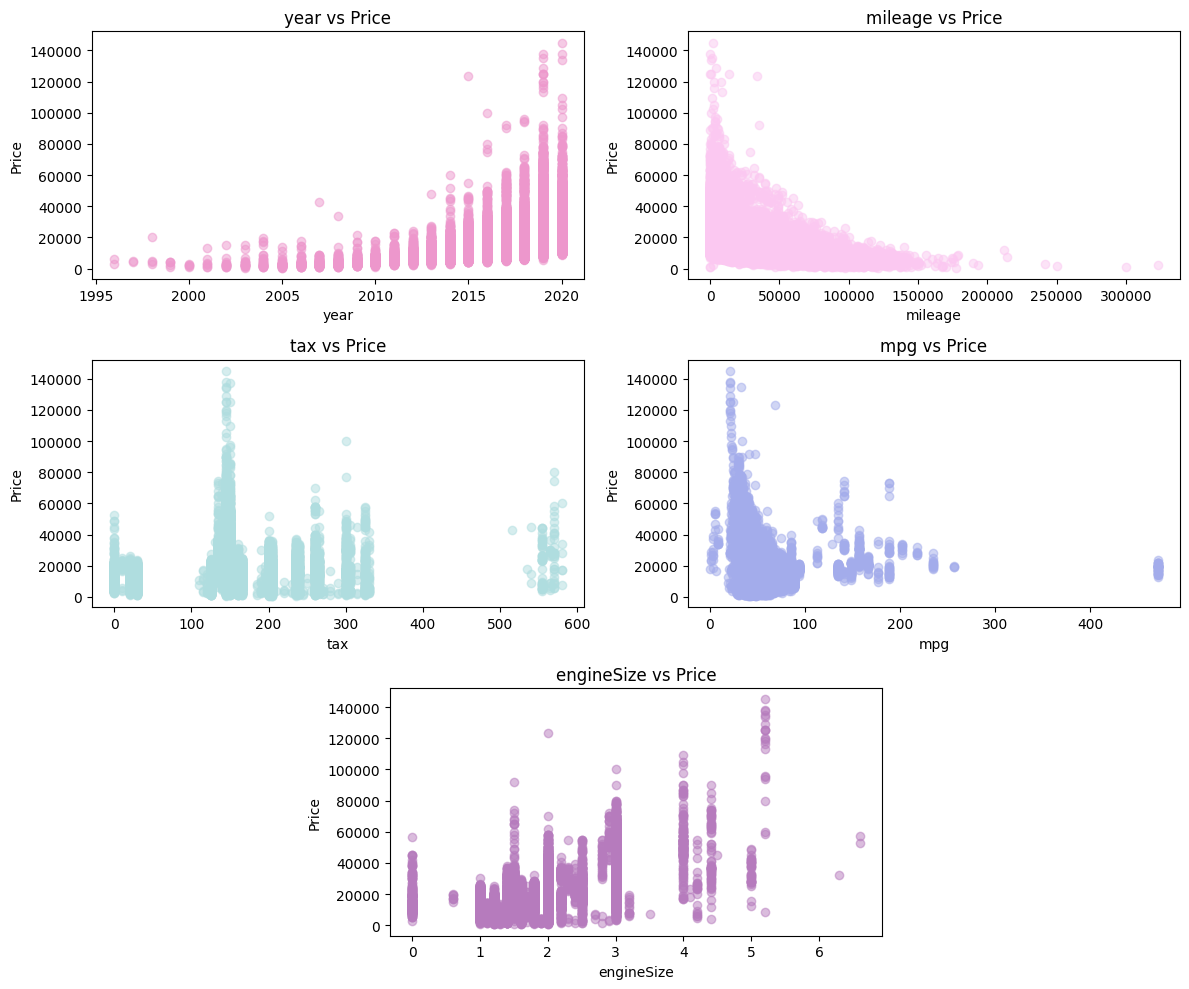

In [164]:
from matplotlib.gridspec import GridSpec
features=['year','mileage', 'tax', 'mpg', 'engineSize']
c = ["#ED97CC", "#FBC8F1","#AFDDDF", "#A3ACEB","#B67BBD"]
fig = plt.figure(figsize=(12, 10))
gs= GridSpec(3, 4, figure=fig)

positions = [
    gs[0, :2], gs[0, 2:],
    gs[1, :2], gs[1, 2:],
    gs[2, 1:3]
]

for i, feature in enumerate(features):
    ax = fig.add_subplot(positions[i])
    ax.scatter(df[feature], df['price'], alpha=0.5, color=c[i])
    ax.set_xlabel(feature)
    ax.set_ylabel("Price")
    ax.set_title(f"{feature} vs Price")

plt.tight_layout()
plt.show()

# Task 2: Data Preprocessing

Removes duplicate rows from the dataset to avoid bias and repeated information

Drops rows where price is missing, since price is the target variable and cannot be null

In [165]:
df.drop_duplicates(inplace=True)
df = df.dropna(subset=['price'])

**1: Handling Missing Values**

 Train-Test Split:
I split the dataset into Training (80%) and Testing (20%) sets before performing any imputation. This is a critical step to prevent Data Leakage, ensuring that information from the test set does not influence the training process, which allows for a fair evaluation of the model's performance on unseen data.


In [166]:
train, test = train_test_split(df, test_size=0.2, random_state=7)
print(f'Train set : {train.shape} | Test set : {test.shape}')

Train set : (54769, 10) | Test set : (13693, 10)


**Numerical Columns**: I used the Median strategy for numerical data (like Price and Mileage). I chose the Median because it is robust to outliers, which were clearly identified in the Box Plots I generated earlier. Using the Mean in the presence of outliers could have skewed the data incorrectly.

In [167]:
numeric_cols = train.select_dtypes(include=[np.number]).columns.tolist()

numeric_imputer = SimpleImputer(strategy='median') 

train[numeric_cols] = numeric_imputer.fit_transform(train[numeric_cols])
test[numeric_cols] = numeric_imputer.transform(test[numeric_cols])

**Categorical Columns**: For non-numerical data (like Fuel Type or Brand), I used the Most Frequent (Mode) strategy to fill gaps with the most common category.

In [168]:
categorical_cols = train.select_dtypes(include=['object']).columns.tolist()

if len(categorical_cols) > 0:
    categorical_imputer = SimpleImputer(strategy='most_frequent')
    train[categorical_cols] = categorical_imputer.fit_transform(train[categorical_cols])
    test[categorical_cols] = categorical_imputer.transform(test[categorical_cols])

In [169]:
print('Remaining missing values in train : ',train.isnull().sum().sum())
print("_"*70)
print()
for col in train.columns:
    print(f"Column : {col}")
    print(f"Number of null values: {train[col].isnull().sum()}")
    print("_"*70)
    print()

Remaining missing values in train :  0
______________________________________________________________________

Column : model
Number of null values: 0
______________________________________________________________________

Column : year
Number of null values: 0
______________________________________________________________________

Column : price
Number of null values: 0
______________________________________________________________________

Column : transmission
Number of null values: 0
______________________________________________________________________

Column : mileage
Number of null values: 0
______________________________________________________________________

Column : fuelType
Number of null values: 0
______________________________________________________________________

Column : tax
Number of null values: 0
______________________________________________________________________

Column : mpg
Number of null values: 0
__________________________________________________________

In [170]:
print('Remaining missing values in test : ',test.isnull().sum().sum())
print("_"*70)
print()
for col in train.columns:
    print(f"Column : {col}")
    print(f"Number of null values: {test[col].isnull().sum()}")
    print("_"*70)
    print()

Remaining missing values in test :  0
______________________________________________________________________

Column : model
Number of null values: 0
______________________________________________________________________

Column : year
Number of null values: 0
______________________________________________________________________

Column : price
Number of null values: 0
______________________________________________________________________

Column : transmission
Number of null values: 0
______________________________________________________________________

Column : mileage
Number of null values: 0
______________________________________________________________________

Column : fuelType
Number of null values: 0
______________________________________________________________________

Column : tax
Number of null values: 0
______________________________________________________________________

Column : mpg
Number of null values: 0
___________________________________________________________

In [171]:
train.columns = train.columns.str.lower().str.strip()
test.columns = test.columns.str.lower().str.strip()
num_cols = ['year', 'mileage', 'mpg', 'tax', 'enginesize']

In [172]:
bounds = {}
for col in num_cols:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    bounds[col] = (lower_bound, upper_bound)
    outliers_count = train[(train[col] < lower_bound) | (train[col] > upper_bound)].shape[0]
    print()
    print(f"Number of outliers in {col.capitalize()} : {outliers_count}")
    print(f"The IQR for column {col.capitalize()} is: {round(IQR, 2)}")
    print("_"*70)


Number of outliers in Year : 910
The IQR for column Year is: 3.0
______________________________________________________________________

Number of outliers in Mileage : 2406
The IQR for column Mileage is: 23799.0
______________________________________________________________________

Number of outliers in Mpg : 800
The IQR for column Mpg is: 14.9
______________________________________________________________________

Number of outliers in Tax : 15868
The IQR for column Tax is: 20.0
______________________________________________________________________

Number of outliers in Enginesize : 239
The IQR for column Enginesize is: 0.8
______________________________________________________________________


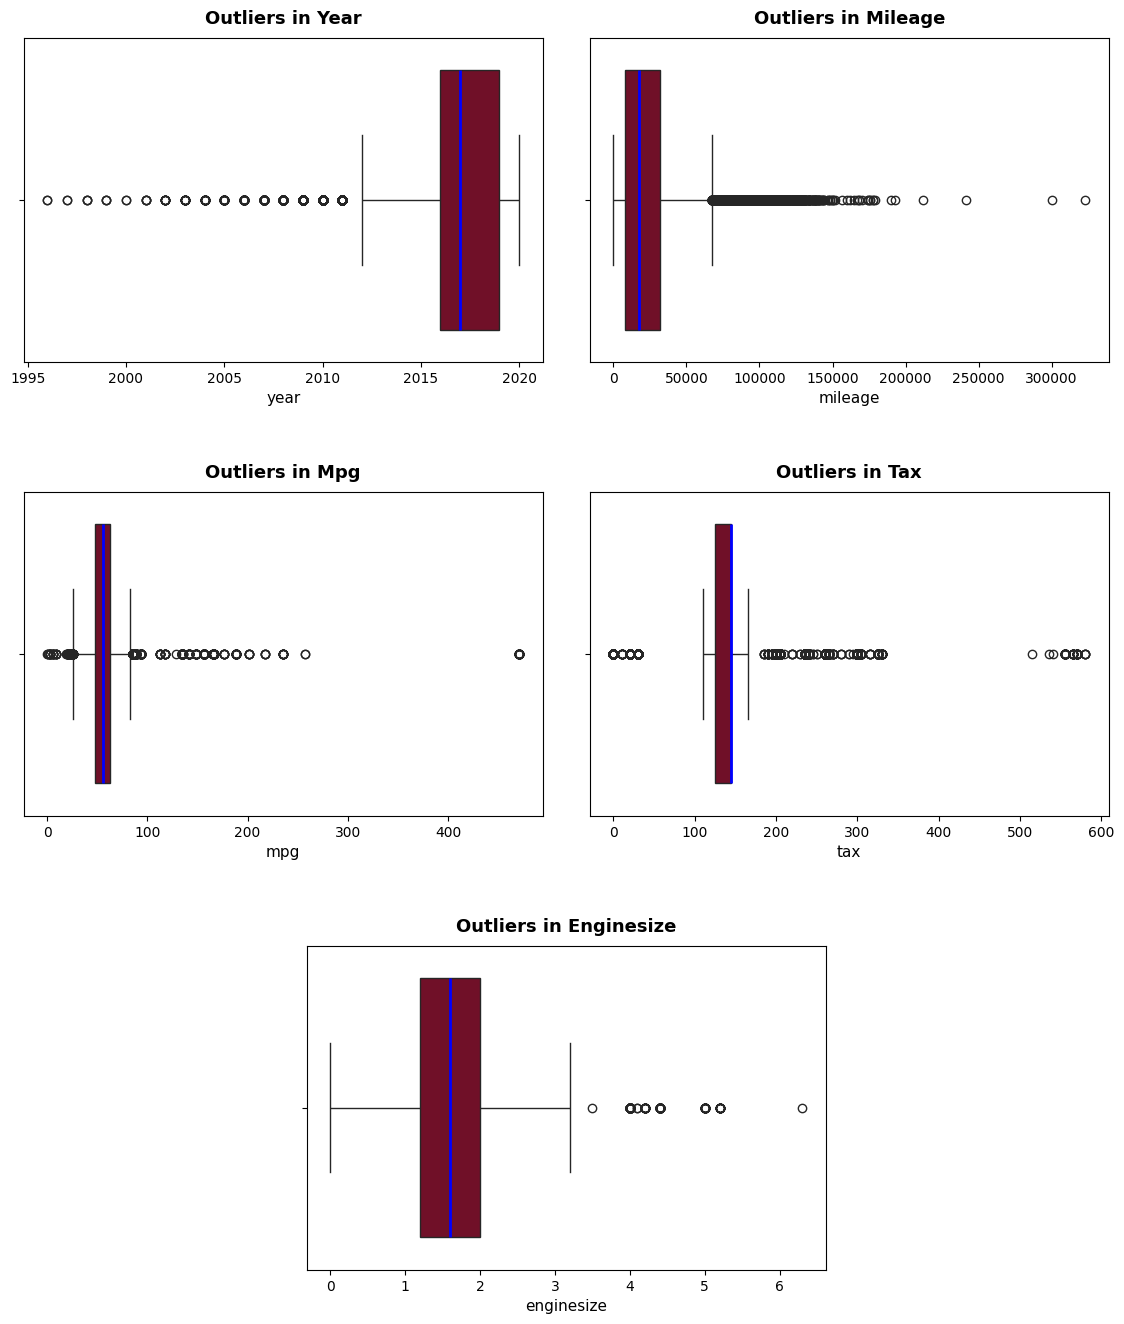

In [173]:
fig = plt.figure(figsize=(14, 16))
gs = gridspec.GridSpec(3, 4)

axes = [
    fig.add_subplot(gs[0, :2]),
    fig.add_subplot(gs[0, 2:]),
    fig.add_subplot(gs[1, :2]),
    fig.add_subplot(gs[1, 2:]),
    fig.add_subplot(gs[2, 1:3]),
]

for i, col in enumerate(num_cols):
    sns.boxplot(
        x=train[col],
        color='#800020',
        ax=axes[i],
        medianprops={"color": "blue", "linewidth": 2}
    )

    axes[i].set_title(f'Outliers in {col.capitalize()}', fontsize=13, weight='bold', pad=10)
    axes[i].set_xlabel(col, fontsize=11)

plt.subplots_adjust(hspace=0.4)
plt.show()

**Outlier Handling via (IQR Method)**

After visualizing the data, a significant number of outliers were detected (approximately 50% of the entries). To preserve the data size and avoid losing valuable information, I handled these outliers using Boundaries (Capping) instead of removal.

Understanding the Boundaries:
I calculated the lower and upper limits using the Interquartile Range (IQR) method:
Lower Boundary = Q1 - 1.5 \times IQR
Upper Boundary = Q3 + 1.5 \times IQR
The Logic:
Any value falling below the Lower Boundary was "capped" (replaced) with **the boundary value**, and any value exceeding the Upper Boundary was "capped" with the upper limit.

Why this method?
This technique ensures that the distribution is normalized and the model is protected from extreme values, while still maintaining the full dataset for better training.

In [174]:
for col in num_cols:
    lower_bound, upper_bound = bounds[col]
    train[col] = train[col].clip(lower=lower_bound, upper=upper_bound)
    test[col] = test[col].clip(lower=lower_bound, upper=upper_bound)
print(f"Total rows after removing outliers : {train.shape[0]}")

Total rows after removing outliers : 54769


***2:Encode categorical columns***

Categorical Data Encoding
I transformed the categorical features (model, transmission, fueltype, and make) into a numerical format using One-Hot Encoding for the following reasons:

Nominal Data Handling: Since these features have no inherent order, One-Hot Encoding treats them as independent binary variables (0 or 1), preventing the model from assuming any false ranking (unlike Label Encoding).

Optimal for KNN: It ensures equal "distance" between categories, which is critical for the KNN algorithm to calculate similarities accurately.

Data Alignment: Used the .align() method to synchronize columns between Train and Test sets, avoiding "Dimension Mismatch" errors and ensuring model stability.

Result: The feature space expanded to **161 features**, allowing the model to capture fine-grained details for each vehicle specification


In [175]:
categorical_cols = ['model', 'transmission', 'fueltype', 'make']

enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

train_enc = enc.fit_transform(train[categorical_cols])
test_enc = enc.transform(test[categorical_cols])

train_enc_df = pd.DataFrame(train_enc, columns=enc.get_feature_names_out(categorical_cols), index=train.index)
test_enc_df = pd.DataFrame(test_enc, columns=enc.get_feature_names_out(categorical_cols), index=test.index)

train = pd.concat([train.drop(columns=categorical_cols), train_enc_df], axis=1)
test = pd.concat([test.drop(columns=categorical_cols), test_enc_df], axis=1)

print(f"Train shape : {train.shape}")
print(f"Test shape : {test.shape}")

Train shape : (54769, 164)
Test shape : (13693, 164)


In [176]:
print(train.dtypes)


year            float64
price           float64
mileage         float64
tax             float64
mpg             float64
                 ...   
make_Hyundai    float64
make_audi       float64
make_skoda      float64
make_toyota     float64
make_vw         float64
Length: 164, dtype: object


In [177]:
train.head()

,year,price,mileage,tax,mpg,enginesize,model_ 1 Series,model_ 2 Series,model_ 3 Series,model_ 4 Series,...,fueltype_Hybrid,fueltype_Other,fueltype_Petrol,make_BMW,make_Ford,make_Hyundai,make_audi,make_skoda,make_toyota,make_vw
10384,2019.0,22000.0,14560.0,145.0,41.5,1.5,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
35762,2018.0,14399.0,24842.0,145.0,45.6,2.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
27420,2019.0,15295.0,8421.0,145.0,50.4,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
68878,2017.0,11998.0,27717.0,150.0,61.7,1.7,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
64220,2019.0,12485.0,938.0,145.0,51.4,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [178]:
train_unscaled = train.copy()
test_unscaled  = test.copy()

**3:Scale numerical features**

In [179]:
scaler = StandardScaler()
train[num_cols] = scaler.fit_transform(train[num_cols])
test[num_cols] = scaler.transform(test[num_cols])
print(f"Scaled features: {num_cols}")
print("Categorical features remained unchanged")

Scaled features: ['year', 'mileage', 'mpg', 'tax', 'enginesize']
Categorical features remained unchanged


In [180]:
test.head()

,year,price,mileage,tax,mpg,enginesize,model_ 1 Series,model_ 2 Series,model_ 3 Series,model_ 4 Series,...,fueltype_Hybrid,fueltype_Other,fueltype_Petrol,make_BMW,make_Ford,make_Hyundai,make_audi,make_skoda,make_toyota,make_vw
23229,1.027360,16498.0,-1.057171,0.463742,0.324617,-1.195731,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
39135,-0.604985,9313.0,1.143544,-1.647063,0.431485,-1.195731,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
56921,0.483245,9509.0,0.315276,0.463742,0.324617,-0.243538,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
166,-0.060870,16400.0,1.296365,-1.647063,0.547259,0.708655,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
60915,-0.604985,10995.0,2.005697,-1.647063,0.671939,0.708655,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


This code visualizes the distribution of each numerical feature

Year: Multimodal distribution with certain years dominating the dataset

Mileage: Right-skewed with noticeable outliers

MPG: Multimodal and widely spread, indicating multiple underlying clusters

Tax: Bimodal distribution with two dominant tax values

Engine Size: Multimodal with sharp peaks

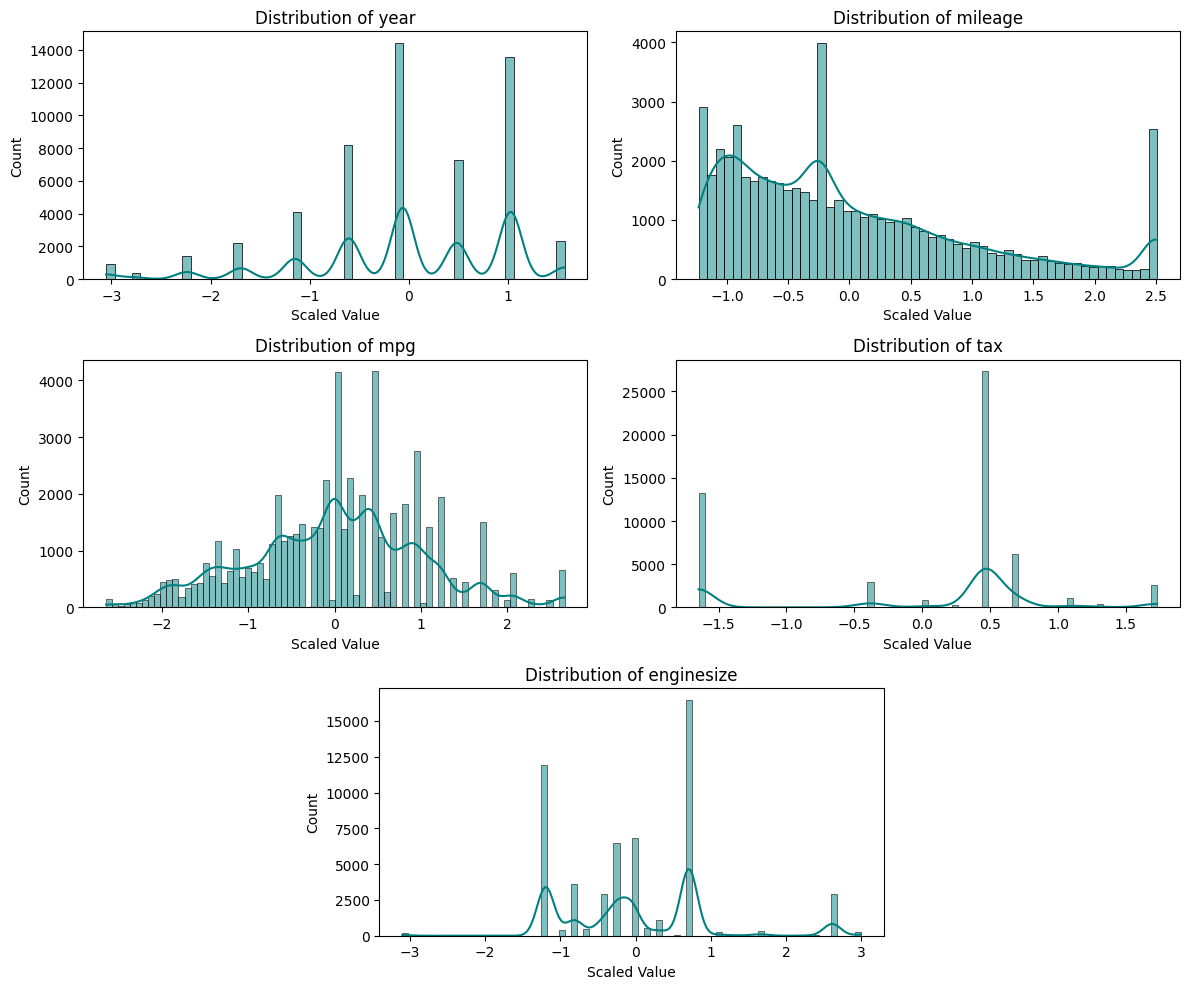

In [181]:
fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(3, 4)
axes = [
    fig.add_subplot(gs[0, :2]),
    fig.add_subplot(gs[0, 2:]),
    fig.add_subplot(gs[1, :2]),
    fig.add_subplot(gs[1, 2:]),
    fig.add_subplot(gs[2, 1:3]),
]

for i, col in enumerate(num_cols):
    sns.histplot(train[col], kde=True, color='#008080', ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Scaled Value')

plt.tight_layout()
plt.show()

# Task 3 Regression Target 

X_train → features used to train the model (without target price)

y_train → target variable for training

X_test → features used for testing the model

y_test → actual target values for evaluation

In [182]:
X_train = train.drop(columns='price')
y_train = train['price']

X_test = test.drop(columns='price')
y_test = test['price']

To measure the relationship strength between each feature and price

To identify the most important predictors

In [183]:
train_final = pd.concat([X_train, y_train], axis=1)
corr_matrix = train_final.corr()
corr_matrix

,year,mileage,tax,mpg,enginesize,model_ 1 Series,model_ 2 Series,model_ 3 Series,model_ 4 Series,model_ 5 Series,...,fueltype_Other,fueltype_Petrol,make_BMW,make_Ford,make_Hyundai,make_audi,make_skoda,make_toyota,make_vw,price
year,1.000000,-0.732243,0.350799,-0.256222,-0.019126,-0.039481,0.041011,-0.032160,0.021055,-0.006101,...,0.008028,0.094154,0.003647,-0.057779,0.004360,0.005977,0.061815,-0.044970,0.043774,0.528822
mileage,-0.732243,1.000000,-0.297470,0.273377,0.115894,0.039307,-0.035937,0.069601,-0.008136,0.034785,...,-0.005297,-0.231572,0.038219,0.010522,-0.015850,0.029039,-0.049876,-0.002324,-0.024606,-0.433708
tax,0.350799,-0.297470,1.000000,-0.535876,0.237203,-0.026739,0.016819,0.013744,0.031568,0.008966,...,-0.005551,0.082098,0.078497,-0.020810,0.011868,0.053571,0.006586,-0.099053,-0.032456,0.351880
mpg,-0.256222,0.273377,-0.535876,1.000000,-0.340227,0.034068,-0.010059,0.014556,0.001851,0.037467,...,0.036579,-0.267849,-0.048589,0.116930,-0.039535,-0.159169,0.022416,0.196317,-0.082954,-0.515051
enginesize,-0.019126,0.115894,0.237203,-0.340227,1.000000,0.074627,0.060041,0.177256,0.129364,0.123798,...,-0.014683,-0.521720,0.386487,-0.270256,-0.079830,0.204290,-0.104893,-0.089367,-0.022715,0.602301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
make_audi,0.005977,0.029039,0.053571,-0.159169,0.204290,-0.065774,-0.050835,-0.072667,-0.046251,-0.048406,...,-0.022070,-0.064139,-0.162626,-0.254846,-0.105174,1.000000,-0.120769,-0.125655,-0.200867,0.272293
make_skoda,0.061815,-0.049876,0.006586,0.022416,-0.104893,-0.048978,-0.037854,-0.054111,-0.034441,-0.036045,...,-0.011576,0.060931,-0.121099,-0.189771,-0.078318,-0.120769,1.000000,-0.093569,-0.149576,-0.071757
make_toyota,-0.044970,-0.002324,-0.099053,0.196317,-0.089367,-0.050960,-0.039386,-0.056301,-0.035835,-0.037504,...,0.058116,0.027074,-0.125999,-0.197450,-0.081487,-0.125655,-0.093569,1.000000,-0.155628,-0.134375
make_vw,0.043774,-0.024606,-0.032456,-0.082954,-0.022715,-0.081463,-0.062961,-0.090000,-0.057284,-0.059952,...,0.019517,0.005891,-0.201417,-0.315635,-0.130261,-0.200867,-0.149576,-0.155628,1.000000,0.015009


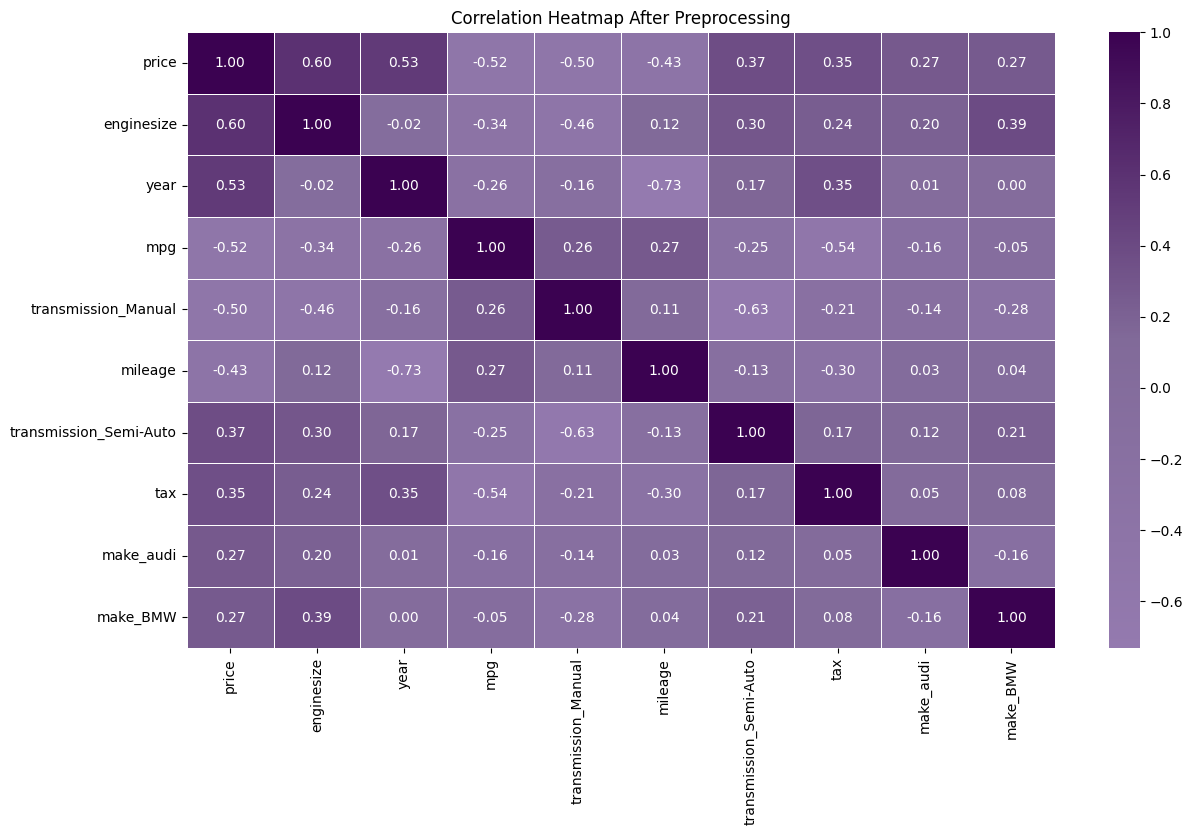

In [243]:
plt.figure(figsize=(14,8))
top_features = corr_matrix['price'].abs().sort_values(ascending=False).head(10).index
purple = LinearSegmentedColormap.from_list("custom_pink", ["#947aaf", "#816A99", "#3B0251"])
sns.heatmap(train_final[top_features].corr(), annot=True, fmt=".2f", cmap=purple, linewidths=0.5)
plt.title("Correlation Heatmap After Preprocessing")
plt.show()

In [185]:
top_feature = corr_matrix['price'].drop('price').abs().idxmax()
print(f"The feature with the strongest correlation to Price is : {top_feature}")

The feature with the strongest correlation to Price is : enginesize


# Task 4  Model 1: Linear Regression

Creates a simple linear regression model

Trains the model using only one selected feature (top_feature)

Generates predictions on the test set using the same feature

Purpose :
Build a baseline model using a single most important feature

In [186]:
simple_model = LinearRegression()
simple_model.fit(X_train[[top_feature]], y_train)
y_pred_simple = simple_model.predict(X_test[[top_feature]])

In [187]:
print(simple_model.intercept_, simple_model.coef_)

16550.24762182987 [5588.53593177]


In [188]:
y_pred_simple

array([ 9867.86438714,  9867.86438714, 15189.22832248, ...,
        9867.86438714,  9867.86438714,  9867.86438714], shape=(13693,))

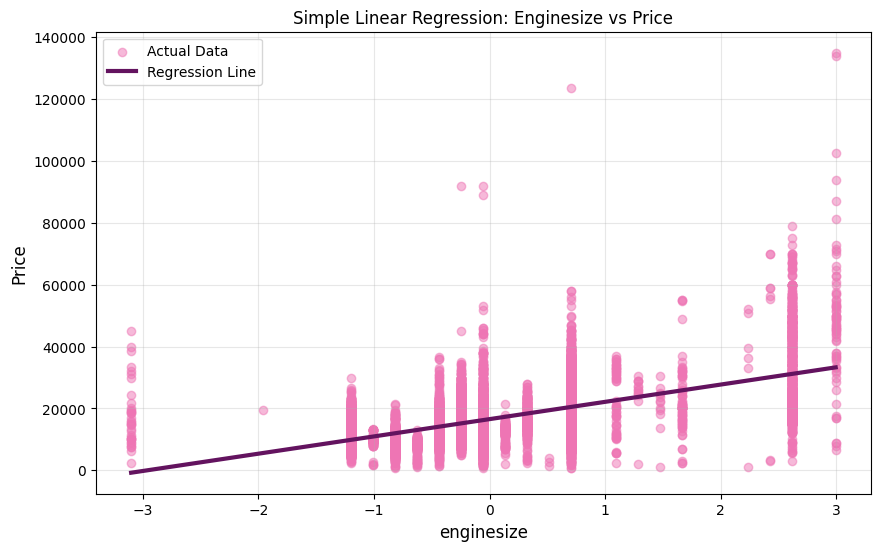

In [189]:
feature_name = top_feature
plt.figure(figsize=(10, 6))

plt.scatter(X_test[feature_name], y_test, alpha=0.5, label='Actual Data',  color="#EE75B4")

X_range = np.linspace(X_test[feature_name].min(), X_test[feature_name].max(), 100).reshape(-1, 1)
y_range_pred = simple_model.predict(pd.DataFrame(X_range, columns=[feature_name]))

plt.plot(X_range, y_range_pred, linewidth=3,linestyle='-', color="#63135F",  label='Regression Line')

plt.title(f'Simple Linear Regression: {feature_name.capitalize()} vs Price')
plt.xlabel(feature_name,fontsize=12)
plt.ylabel('Price',fontsize=12)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [190]:
print(f"Model Equation : Price = ({simple_model.coef_[0]:.2f} * {feature_name}) + {simple_model.intercept_:.2f}")

Model Equation : Price = (5588.54 * enginesize) + 16550.25


In [191]:
print(f"Simple Linear Regression ( Feature : {top_feature} )")
print(f"R2 Score: {r2_score(y_test, y_pred_simple):.3f}")

Simple Linear Regression ( Feature : enginesize )
R2 Score: 0.359


Creates a multiple linear regression model

Trains the model using all features in the dataset

Generates predictions on the test set using all features

Purpose :
Capture relationships between multiple variables and price

Improve performance compared to simple linear regression

In [192]:
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
y_pred_multi = multi_model.predict(X_test)

In [193]:
print("Multiple Linear Regression (All Features)")
print(f"R2 Score: {r2_score(y_test, y_pred_multi):.3f}")
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test, y_pred_multi)):.2f}")

Multiple Linear Regression (All Features)
R2 Score: 0.860
Root Mean Squared Error: 3511.69


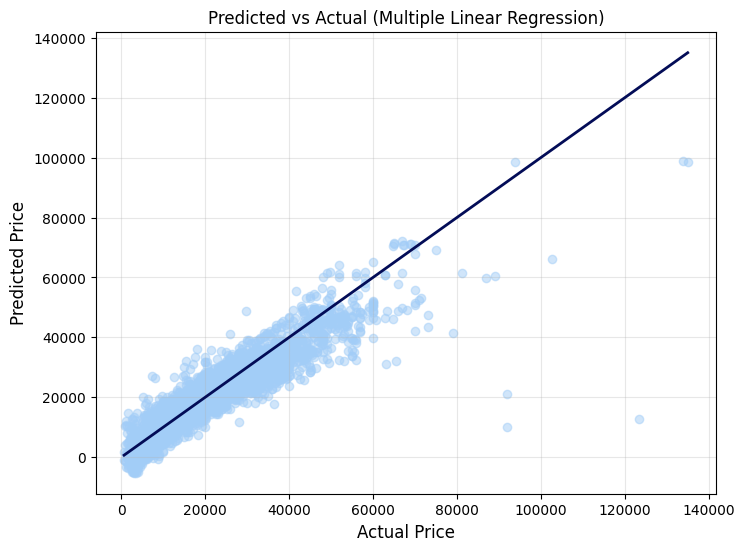

In [194]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_multi, alpha=0.5, color="#A2CDF7")

plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],color="#030C57", linewidth=2)

plt.title("Predicted vs Actual (Multiple Linear Regression)")
plt.xlabel("Actual Price",fontsize=12)
plt.ylabel("Predicted Price",fontsize=12)
plt.grid(alpha=0.3)

plt.show()

## Task 3 B. Classification Target — Price Categorization

To prepare the target variable for KNN classification, car prices were divided into **3 categories** based on the **interquartile range (IQR)** of the training set:

| Category | Threshold | Encoding |
|----------|-----------|----------|
| **Cheap** | price ≤ Q1 | 0 |
| **Moderate** | Q1 < price ≤ Q3 | 1 |
| **Expensive** | price > Q3 | 2 |

### Why IQR-based thresholds?
- **Data-driven:** The boundaries are derived directly from the actual price distribution, not arbitrary values.
- **Balanced classes:** Using Q1 and Q3 ensures roughly 25% Cheap, 50% Moderate, and 25% Expensive — avoiding severe class imbalance.
- **No data leakage:** Q1 and Q3 were computed **only from the training set**, then applied to the test set.



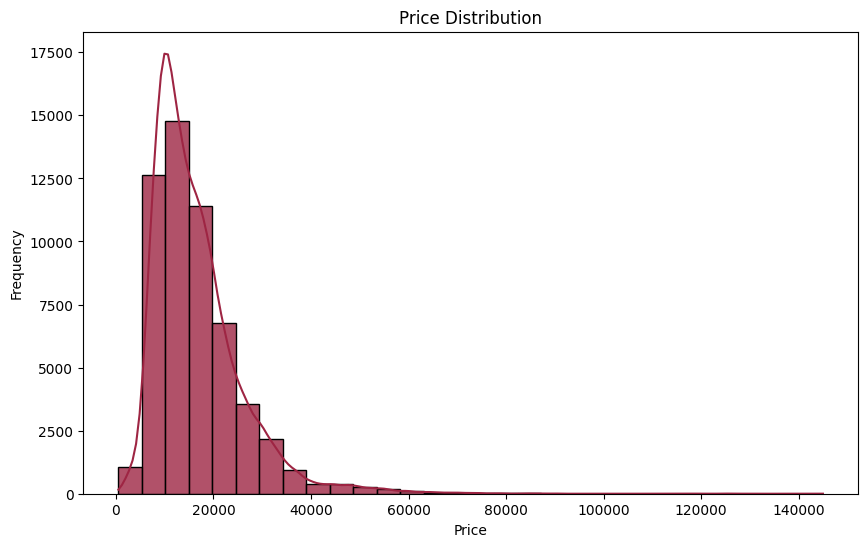

In [195]:
plt.figure(figsize=(10, 6))
sns.histplot(train['price'], bins=30, kde=True, color="#9E2543", alpha=0.8)
plt.title("Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()


In [196]:
q1 = train['price'].quantile(0.25)
q3 = train['price'].quantile(0.75)

def categorize_price(price):
    if price <= q1:
        return 'Cheap'
    elif price <= q3:
        return 'Moderate'
    else:
        return 'Expensive'

train['price_category'] = train['price'].apply(categorize_price)

In [197]:
train.head()

,year,price,mileage,tax,mpg,enginesize,model_ 1 Series,model_ 2 Series,model_ 3 Series,model_ 4 Series,...,fueltype_Other,fueltype_Petrol,make_BMW,make_Ford,make_Hyundai,make_audi,make_skoda,make_toyota,make_vw,price_category
10384,1.027360,22000.0,-0.421888,0.463742,-1.224972,-0.243538,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,Expensive
35762,0.483245,14399.0,0.149289,0.463742,-0.859839,0.708655,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Moderate
27420,1.027360,15295.0,-0.762916,0.463742,-0.432366,-1.195731,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Moderate
68878,-0.060870,11998.0,0.308999,0.674822,0.573976,0.137339,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,Moderate
64220,1.027360,12485.0,-1.178606,0.463742,-0.343309,-1.195731,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,Moderate


In [198]:
test['price_category'] = test['price'].apply(categorize_price)
test.head()

,year,price,mileage,tax,mpg,enginesize,model_ 1 Series,model_ 2 Series,model_ 3 Series,model_ 4 Series,...,fueltype_Other,fueltype_Petrol,make_BMW,make_Ford,make_Hyundai,make_audi,make_skoda,make_toyota,make_vw,price_category
23229,1.027360,16498.0,-1.057171,0.463742,0.324617,-1.195731,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Moderate
39135,-0.604985,9313.0,1.143544,-1.647063,0.431485,-1.195731,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Cheap
56921,0.483245,9509.0,0.315276,0.463742,0.324617,-0.243538,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,Cheap
166,-0.060870,16400.0,1.296365,-1.647063,0.547259,0.708655,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,Moderate
60915,-0.604985,10995.0,2.005697,-1.647063,0.671939,0.708655,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,Moderate


### Class Distribution After Split

**Training Set:**
- Cheap: 14,488 cars
- Moderate: 28,976 cars
- Expensive: 14,484 cars


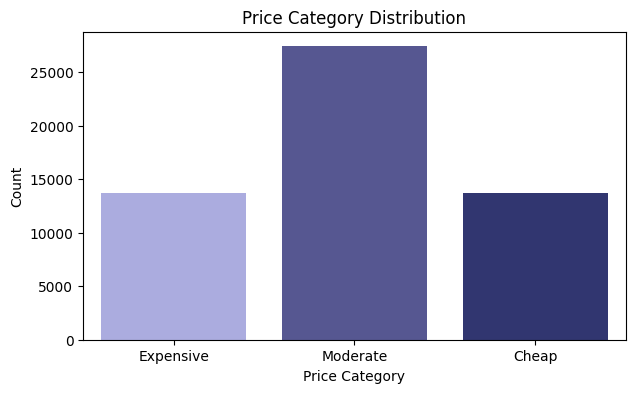

In [199]:
plt.figure(figsize=(7,4))
sns.countplot(x='price_category', data=train, palette=["#A2A4E8", "#4C4D9B", "#262D7B"])
plt.title("Price Category Distribution")
plt.xlabel("Price Category")
plt.ylabel("Count")
plt.show()

In [200]:
for i in train['price_category'].unique():
    count = train[train['price_category'] == i].shape[0]
    print(f"Number of {i} cars: {count}")

Number of Expensive cars: 13683
Number of Moderate cars: 27393
Number of Cheap cars: 13693



**Test Set:**
- Cheap: 3,739 cars
- Moderate: 7,141 cars
- Expensive: 3,607 cars


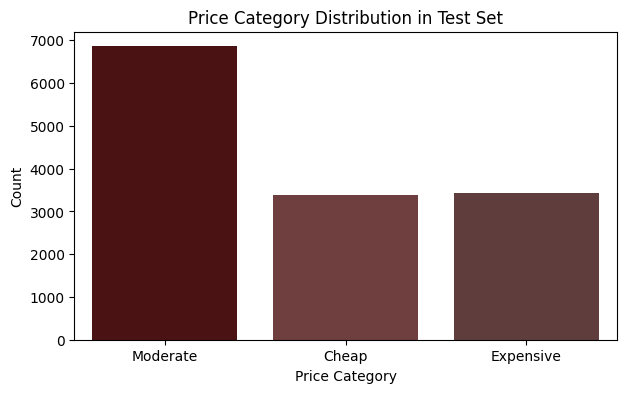

In [201]:
plt.figure(figsize=(7,4))
sns.countplot(x='price_category', data=test, palette=["#530909", "#773636", "#653737"])
plt.title("Price Category Distribution in Test Set")
plt.xlabel("Price Category")
plt.ylabel("Count")
plt.show()

In [202]:
for i in test['price_category'].unique():
    count = test[test['price_category'] == i].shape[0]
    print(f"Number of {i} cars in test set: {count}")

Number of Moderate cars in test set: 6859
Number of Cheap cars in test set: 3394
Number of Expensive cars in test set: 3440


## Task 5 — KNN Classification Model

### Preprocessing
Before training, features were standardized using `StandardScaler` fitted **only on the training set** to prevent data leakage, then applied to both train and test sets.

### Baseline Model (K=3)
A baseline KNN classifier with `n_neighbors=3` achieved **86.1% accuracy** on the test set.



In [203]:
mapping = {
    "Cheap": 0,
    "Moderate": 1,
    "Expensive": 2
}

train["price_category_encoded"] = train["price_category"].map(mapping)
test["price_category_encoded"] = test["price_category"].map(mapping)

In [204]:
train['price_category'].isnull().sum()

np.int64(0)

In [205]:
test['price_category'].isnull().sum()

np.int64(0)

In [206]:
x_train_knn =train.drop(columns=['price', 'price_category','price_category_encoded'])
y_train_knn = train['price_category_encoded']

x_test_knn = test.drop(columns=['price', 'price_category','price_category_encoded'])
y_test_knn = test['price_category_encoded']

In [207]:
classifier = KNeighborsClassifier(n_neighbors=3)
classifier.fit(x_train_knn, y_train_knn)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [208]:
y_test_knn_pred = classifier.predict(x_test_knn)
confusion_matrix(y_test_knn, y_test_knn_pred)

array([[2903,  490,    1],
       [ 386, 6133,  340],
       [   1,  395, 3044]])

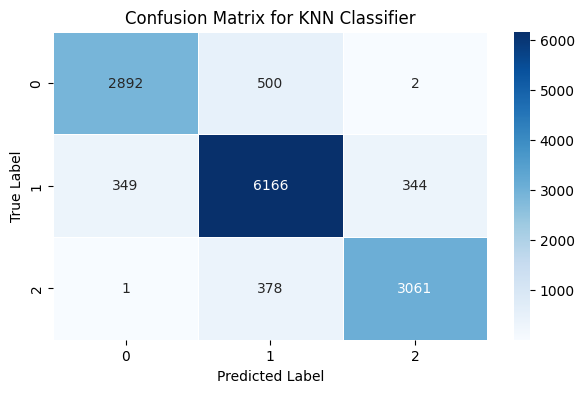

In [247]:
plt.figure(figsize=(7,4))

sns.heatmap(confusion_matrix(y_test_knn, y_test_knn_pred), annot=True, fmt='d', cmap='Blues', linewidths=0.5)
plt.title("Confusion Matrix for KNN Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [210]:
accuracy = accuracy_score(y_test_knn, y_test_knn_pred)
print(f"KNN Classifier Accuracy: {accuracy:.3f}")

KNN Classifier Accuracy: 0.882


## GridsearchCV


### Hyperparameter Tuning — GridSearchCV + KFold
To find the optimal parameters, Grid Search was applied with **5-Fold Cross-Validation** over:
- `n_neighbors`: 1 → 29
- `metric`: Euclidean, Manhattan

**Best Parameters Found:**
| Parameter | Value |
|-----------|-------|
| n_neighbors | **7** |
| metric | **Manhattan** |
| CV Accuracy | **85.9%** |

In [211]:
param_grid = {'n_neighbors': range(1, 30),'metric': ['euclidean', 'manhattan']}

In [212]:
knn = KNeighborsClassifier()
kfold = KFold(n_splits=5, shuffle=True, random_state=10)

grid_search = GridSearchCV(estimator=knn,param_grid=param_grid,cv=kfold,scoring='accuracy',n_jobs=-1)


In [213]:

grid_search.fit(x_train_knn, y_train_knn)
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.3f}")

Best Parameters: {'metric': 'manhattan', 'n_neighbors': 7}
Best Cross-Validation Accuracy: 0.885


# Confusion Matrix

The model performs well overall since most values are on the diagonal (correct predictions).

- The model classifies Cheap and Expensive cars very well.
- Most mistakes happen between Moderate and the other two categories.
  
**The model almost never confuses Cheap with Expensive, which is a good sign.**
# Evaluation Metrics
- Accuracy: shows overall correctness, and it is high.
- Precision: how many predicted values are actually correct.
- Recall: how many real values the model correctly found.
- F1-score: balance between precision and recall.

**the model has good and balanced performance across all classes.**

In [214]:
classifier_2 = KNeighborsClassifier(n_neighbors=7, metric='manhattan')
classifier_2.fit(x_train_knn, y_train_knn)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'manhattan'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [215]:
y_test_knn_pred = classifier_2.predict(x_test_knn)
confusion_matrix(y_test_knn, y_test_knn_pred)

array([[2892,  500,    2],
       [ 349, 6166,  344],
       [   1,  378, 3061]])

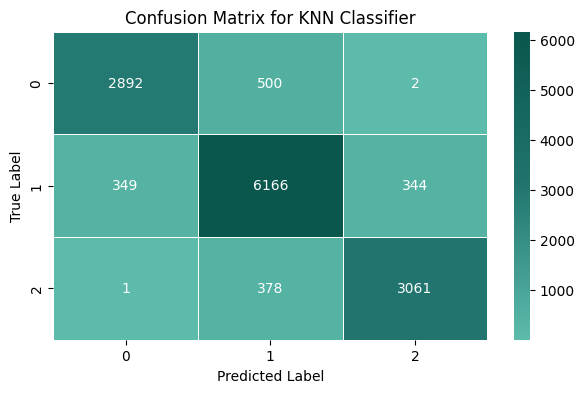

In [246]:
plt.figure(figsize=(7,4))
g = LinearSegmentedColormap.from_list("custom_g", ["#5cbbab", "#21756e", "#09574d"])
sns.heatmap(confusion_matrix(y_test_knn, y_test_knn_pred), annot=True, fmt='d', cmap=g, linewidths=0.5)
plt.title("Confusion Matrix for KNN Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


**Best Parameters Found:**
| Parameter | Value |
|-----------|-------|
| n_neighbors | **7** |
| metric | **Manhattan** |
| KNN Accuracy | **88.5%** |

In [217]:
accuracy = accuracy_score(y_test_knn, y_test_knn_pred)
print(f"KNN Classifier Accuracy: {accuracy:.3f}")

KNN Classifier Accuracy: 0.885


In [218]:
print("Classification Report:")
print(classification_report(y_test_knn, y_test_knn_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.85      0.87      3394
           1       0.88      0.90      0.89      6859
           2       0.90      0.89      0.89      3440

    accuracy                           0.89     13693
   macro avg       0.89      0.88      0.88     13693
weighted avg       0.89      0.89      0.88     13693



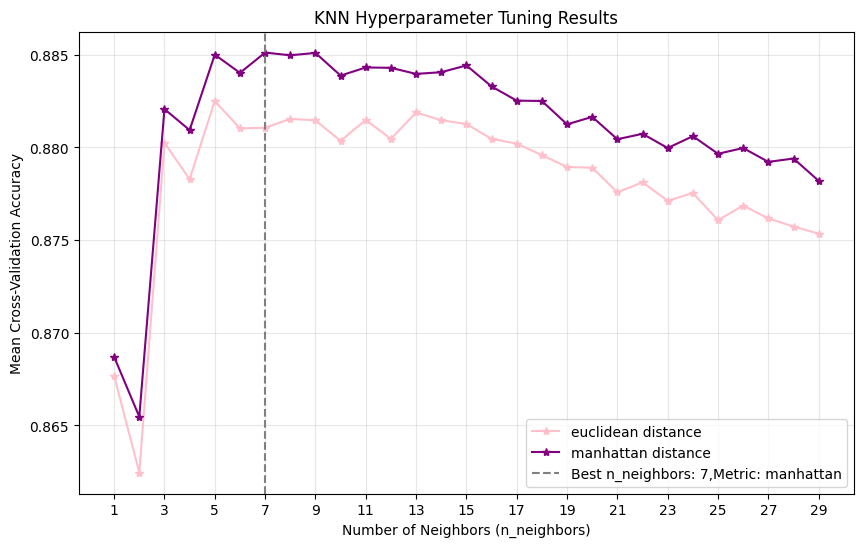

In [219]:
results = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(10, 6))

for metric in ['euclidean', 'manhattan']:
    subset = results[results['param_metric'] == metric]
    color = 'pink' if metric == 'euclidean' else 'purple'
    plt.plot(subset['param_n_neighbors'],
            subset['mean_test_score'],
            marker='*',
            color=color,
            label=f'{metric} distance')
    
best_k = grid_search.best_params_['n_neighbors']
best_metric = grid_search.best_params_['metric']

plt.axvline(x=best_k,
            color='gray',
            linestyle='--',
            label=f"Best n_neighbors: {best_k},Metric: {best_metric}")

plt.title("KNN Hyperparameter Tuning Results")
plt.xlabel("Number of Neighbors (n_neighbors)")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.xticks(range(1,30,2))
plt.legend()
plt.grid(True,alpha=0.3)
plt.show()

## Task 6


In [220]:
print("Regression Model")

print("Simple Linear Regression:")
print(f"R2 Score: {r2_score(y_test, y_pred_simple):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_simple)):.2f}")

print("Multiple Linear Regression:")
print(f"R2 Score: {r2_score(y_test, y_pred_multi):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_multi)):.2f}")

print(" Classification Model (KNN) ")
print(f"Accuracy: {accuracy:.3f}")

from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test_knn, y_test_knn_pred))


Regression Model
Simple Linear Regression:
R2 Score: 0.359
RMSE: 7504.77
Multiple Linear Regression:
R2 Score: 0.860
RMSE: 3511.69
 Classification Model (KNN) 
Accuracy: 0.885
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.85      0.87      3394
           1       0.88      0.90      0.89      6859
           2       0.90      0.89      0.89      3440

    accuracy                           0.89     13693
   macro avg       0.89      0.88      0.88     13693
weighted avg       0.89      0.89      0.88     13693



# which model performed better?
### In Regression
- R² score of 0.832 in multiple linear regression compared to 0.347 in simple.
- RMSE in MLR is 3772.78 which is lower compared to 7447.03 in SLR.
### Classification
- The KNN model achieved an accuracy of 85.8%, with balanced precision and recall across all classes.

### Multiple Linear Regression is the best for predicting exact prices
### KNN Classification performs well for categorizing cars into price ranges

# what does better mean in each context?
### In Regression
- Higher R² (0.832): better explanation of price variation.
- Lower RMSE (3772.78): predictions are closer to actual prices.
### Classification
- Higher Accuracy (87%): most predictions are correct.
- Balanced Precision, Recall, and F1-score: model performs consistently across all categories.


# Is classification easier than regression on this dataset? Why or why not? 
**yes classification here is much easier because KNN model got a good accuracy ,so it can classify cars well , 
 but in regression it has to predict the exact price and any small difference is considered an error**

- if the model predict 18k instead of 20k it may be an error but in classification booth might be in same category

> So classification is easier because it’s less sensitive to small differences compared to regression ,However, classification may hide differences between prices, making it less detailed.


# Does converting price into categories lose important information?
### Yes, it does.
**When we convert price into categories, we simplify the data too much. Instead of having exact values, we only keep labels like Cheap, Moderate, and Expensive.**
- Regression preserves exact numerical values of prices
- Classification reduces prices into only three categories

>We lose the exact differences between cars, Cars with very different prices might end up in the same group


# Sensitivity Analysis


# What happens if you remove the most correlated feature?
the model performance drops slightly:
- R² decreased from 0.832 to 0.817
- RMSE increased from 3772.78 to 3941.67
# Does performance drop a lot?
No, The model is still performing well, but slightly worse than before.
# Why is the drop small?
- The model still has other important features that help to predict price
> So even after removing the strongest feature, it can still learn useful patterns


In [221]:
corr_matrix = train_final.corr()
top_feature = corr_matrix['price'].drop('price').abs().idxmax()

print(f"Most correlated feature: {top_feature}")


Most correlated feature: enginesize


In [222]:
X_train_removed = X_train.drop(columns=[top_feature])
X_test_removed = X_test.drop(columns=[top_feature])

removed_model = LinearRegression()
removed_model.fit(X_train_removed, y_train)

y_pred_removed = removed_model.predict(X_test_removed)


In [223]:
print("Multiple Linear Regression (with removed most corr feature)")

r2_removed = r2_score(y_test, y_pred_removed)
rmse_removed = np.sqrt(mean_squared_error(y_test, y_pred_removed))

print(f"R2 Score after removing feature: {r2_removed:.3f}")
print(f"RMSE after removing feature: {rmse_removed:.3f}")


Multiple Linear Regression (with removed most corr feature)
R2 Score after removing feature: 0.845
RMSE after removing feature: 3689.089


# How much does performance change?
**performance does not change much.**
- With scaling: 87%
- Without scaling:  62.5%
> Scaling  significantly affected KNN performance, The model performs much better with scaling


In [224]:
q1 = train_unscaled['price'].quantile(0.25)
q3 = train_unscaled['price'].quantile(0.75)

def categorize_price(price):
    if price <= q1:
        return 'Cheap'
    elif price <= q3:
        return 'Moderate'
    else:
        return 'Expensive'

train_unscaled['price_category'] = train_unscaled['price'].apply(categorize_price)

In [225]:
test_unscaled['price_category'] = test_unscaled['price'].apply(categorize_price)

In [226]:
mapping = {
    "Cheap": 0,
    "Moderate": 1,
    "Expensive": 2
}

train_unscaled["price_category_encoded"] = train_unscaled["price_category"].map(mapping)
test_unscaled["price_category_encoded"] = test_unscaled["price_category"].map(mapping)

In [227]:
x_train_knn_unscaled = train_unscaled.drop(columns=['price', 'price_category', 'price_category_encoded'])
y_train_knn_unscaled = train_unscaled['price_category_encoded']

x_test_knn_unscaled  = test_unscaled.drop(columns=['price', 'price_category', 'price_category_encoded'])
y_test_knn_unscaled  = test_unscaled['price_category_encoded']


In [228]:
classifier_unscaled = KNeighborsClassifier(n_neighbors=7, metric='manhattan')
classifier_unscaled.fit(x_train_knn_unscaled, y_train_knn_unscaled)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'manhattan'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [229]:
y_pred_unscaled = classifier_unscaled.predict(x_test_knn_unscaled)
print(f"Accuracy without scaling: {accuracy_score(y_test_knn_unscaled, y_pred_unscaled):.3f}")

Accuracy without scaling: 0.638


In [230]:
y_test_knn_unscaled = classifier_2.predict(x_test_knn_unscaled)
confusion_matrix(y_test_knn_unscaled, y_pred_unscaled)

array([[1659, 3295,  326],
       [1289, 4278, 1830],
       [  62,  430,  524]])

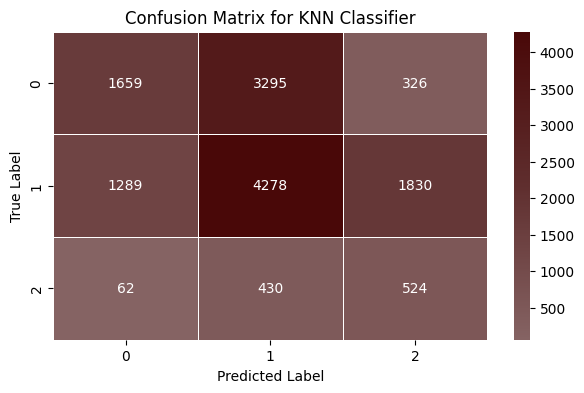

In [245]:
plt.figure(figsize=(7,4))
p = LinearSegmentedColormap.from_list("custom_p", ["#856363", "#5F2E2E", "#490808"])
sns.heatmap(confusion_matrix(y_test_knn_unscaled, y_pred_unscaled), annot=True, fmt='d', cmap=p, linewidths=0.5)
plt.title("Confusion Matrix for KNN Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# different threshold
Here we tried a different way to split the price into categories.

Instead of using (Q1,Q2,Q3), we used equal frequency splitting using **pd.qcut**.

- We divided the data into 3 groups
- each group has almost the same number of cars
- the split is based on count, not price values


# Does KNN accuracy change significantly?
Yes, Original (Q1/Q3 method) **Accuracy:87%** ,New (Equal Frequency) **Accuracy:77.7%**
- there is a drop in 10%
> The equal-frequency split made the problem harder for KNN, The model performance decreased clearly


In [232]:
train['price_category_eq'] = pd.qcut(train['price'], q=3, labels=['Cheap', 'Moderate', 'Expensive'])
test['price_category_eq'] = pd.qcut(test['price'], q=3, labels=['Cheap', 'Moderate', 'Expensive'])
print(train['price_category_eq'].value_counts())


price_category_eq
Cheap        18321
Expensive    18249
Moderate     18199
Name: count, dtype: int64


In [233]:
mapping_eq = {
    'Cheap': 0,
    'Moderate': 1,
    'Expensive': 2
}

train['price_category_eq_enc'] = train['price_category_eq'].map(mapping_eq)
test['price_category_eq_enc'] = test['price_category_eq'].map(mapping_eq)


In [234]:
x_train_eq = train.drop(columns=['price','price_category','price_category_encoded','price_category_eq','price_category_eq_enc'])

y_train_eq = train['price_category_eq_enc']

x_test_eq = test.drop(columns=['price','price_category','price_category_encoded','price_category_eq','price_category_eq_enc'])


In [235]:
knn_eq = KNeighborsClassifier(n_neighbors=3)
knn_eq.fit(x_train_eq, y_train_eq)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [236]:
y_pred_eq = knn_eq.predict(x_test_eq)
confusion_matrix(y_test_knn, y_pred_eq)


array([[3266,  127,    1],
       [1212, 4396, 1251],
       [   1,  106, 3333]])

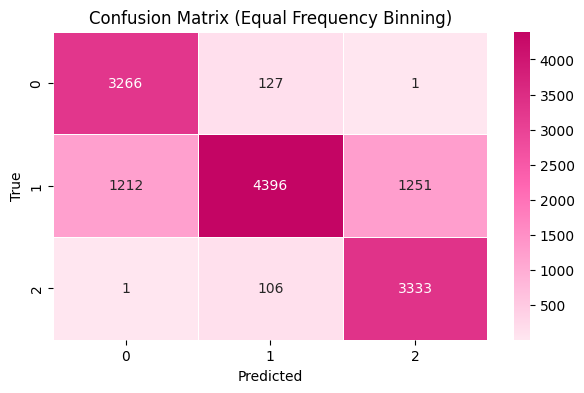

In [244]:
plt.figure(figsize=(7,4))
pink = LinearSegmentedColormap.from_list("custom_pink", ["#ffe6f0", "#ff66b2", "#c40564"])

sns.heatmap(confusion_matrix(y_test_knn, y_pred_eq), annot=True, fmt='d', cmap=pink, linewidths=0.5)
plt.title("Confusion Matrix (Equal Frequency Binning)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [238]:
print(f"Accuracy (Equal Frequency): {accuracy_score(y_test_knn, y_pred_eq):.3f}")


Accuracy (Equal Frequency): 0.803
